In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Load datasets
orders = pd.read_csv("orders.csv")
customers = pd.read_csv("customers.csv")
products = pd.read_csv("products.csv")
regions = pd.read_csv("regions.csv")

# Quick data overview
print("--- Orders Info ---")
print(orders.info())
print("\n--- Summary Statistics ---")
print(orders[["sales", "discount", "profit"]].describe())

# Merge datasets for comprehensive EDA
df = orders.merge(customers, on="customer_id", how="left")
df = df.merge(products, on="product_id", how="left")
df = df.merge(regions, on="region_id", how="left")

print(
    f"\nSuccessfully merged dataset shape: {df.shape}"
)  # Should match expected row count

--- Orders Info ---
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   row_id       9994 non-null   int64  
 1   order_id     9994 non-null   str    
 2   order_date   9994 non-null   str    
 3   ship_date    9994 non-null   str    
 4   ship_mode    9994 non-null   str    
 5   customer_id  9994 non-null   str    
 6   product_id   9994 non-null   str    
 7   region_id    9994 non-null   int64  
 8   sales        9994 non-null   float64
 9   quantity     9994 non-null   int64  
 10  discount     9994 non-null   float64
 11  profit       9994 non-null   float64
dtypes: float64(3), int64(3), str(6)
memory usage: 937.1 KB
None

--- Summary Statistics ---
              sales     discount       profit
count   9994.000000  9994.000000  9994.000000
mean     229.858001     0.156203    28.656896
std      623.245101     0.206452   234.260108
min        0.444000

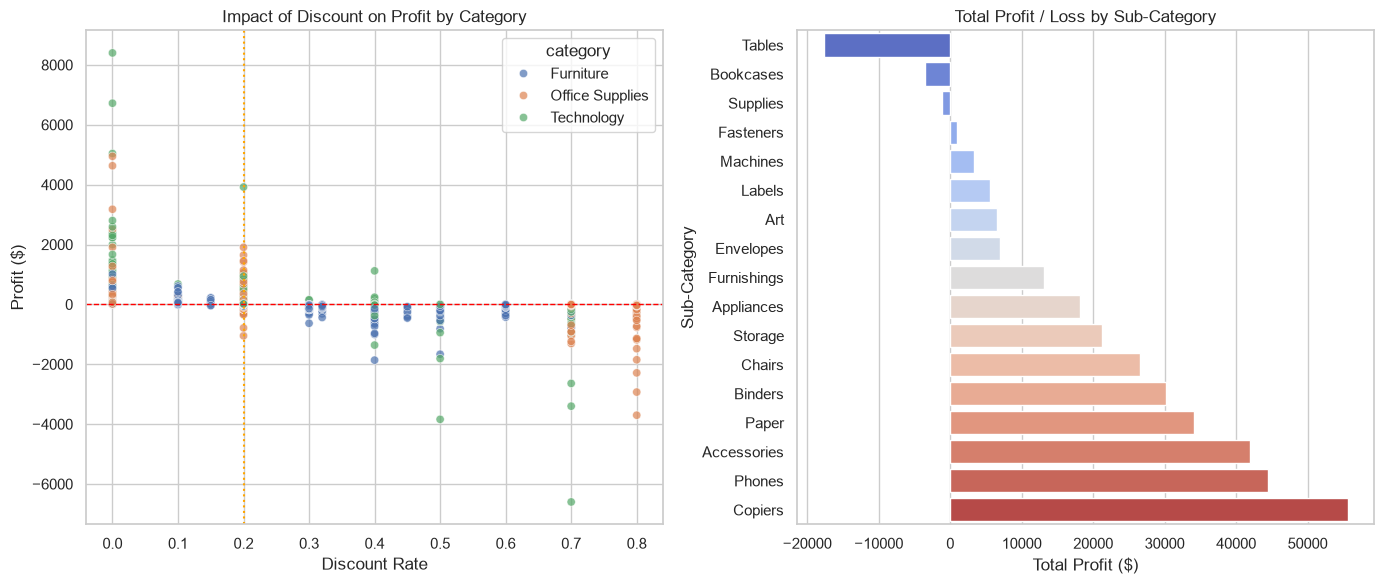

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 6))

# 1. Scatter plot: Discount vs Profit
plt.subplot(1, 2, 1)
sns.scatterplot(
    data=df,
    x="discount",
    y="profit",
    hue="category",
    palette="deep",
    alpha=0.7,
)
plt.axhline(0, color="red", linestyle="--", linewidth=1)
plt.axvline(0.2, color="orange", linestyle=":", linewidth=1.5)
plt.title("Impact of Discount on Profit by Category")
plt.xlabel("Discount Rate")
plt.ylabel("Profit ($)")

# 2. Bar plot: Total Profit by Sub-Category
plt.subplot(1, 2, 2)
subcat_profit = (
    df.groupby("sub_category")["profit"].sum().sort_values().reset_index()
)
sns.barplot(
    data=subcat_profit,
    x="profit",
    y="sub_category",
    palette="coolwarm",
    hue="sub_category",
    legend=False,
)
plt.title("Total Profit / Loss by Sub-Category")
plt.xlabel("Total Profit ($)")
plt.ylabel("Sub-Category")

plt.tight_layout()
plt.show()

--- Correlation Matrix ---
          sales  quantity  discount  profit
sales     1.000     0.201    -0.028   0.479
quantity  0.201     1.000     0.009   0.066
discount -0.028     0.009     1.000  -0.219
profit    0.479     0.066    -0.219   1.000


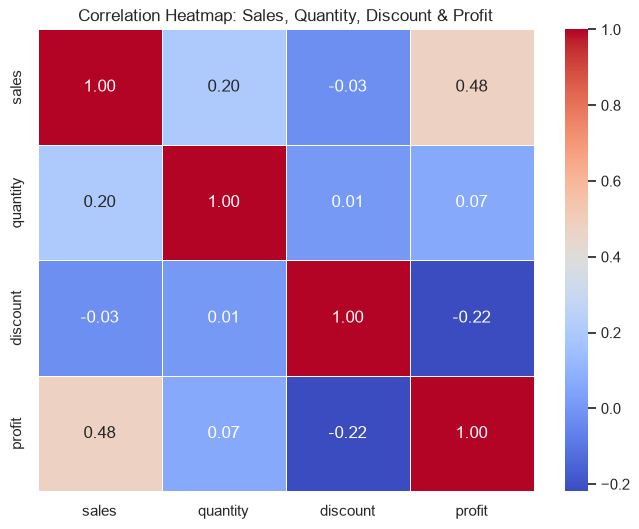

In [3]:
# Statistical Correlation Matrix
numeric_cols = ["sales", "quantity", "discount", "profit"]
correlation_matrix = df[numeric_cols].corr()

print("--- Correlation Matrix ---")
print(round(correlation_matrix, 3))

# Visualize Correlation Heatmap
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5
)
plt.title("Correlation Heatmap: Sales, Quantity, Discount & Profit")
plt.show()